# 19. Фотографии, лучи и камеры COLMAP

[План курса](../../README_ru.md)

Два снимка скульптуры похожи. На первом край каменного выступа закрывает кусок фона, на втором между ними уже видна щель. Этот маленький сдвиг позволяет восстановить глубину. Однотонное пятно на стене бесполезно, пока мы не можем уверенно опознать его же на втором кадре.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'

import photo_diagnostics as inspect_photo

## Две камеры у стола

Начнём с почти игрушечной съёмки. Оптические оси параллельны, правая камера на 40 см правее левой. Между ними расстояние B, его называют базой. Оранжевый луч проходит через метку правого снимка, синий — левого. Оба лежат в одной горизонтальной плоскости. Маленькая ошибка в пикселях сбивает точку их встречи. На рисунке сверху глубина растёт от камер вверх.


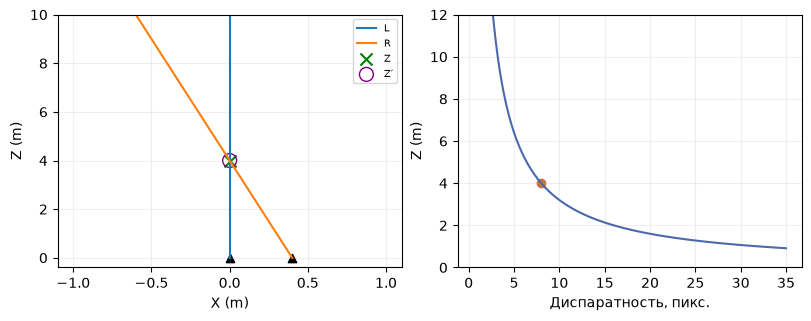

In [2]:
display(rays_figure(lang=lang)); plt.close()
controls(lambda B, du, Z: rays_figure(B, du, Z, lang),
         B=(0,1,.01,.4), du=(-4,4,.1,0), Z=(1,8,.1,4))


## Что увидит фотоаппарат, если обойти предмет дугой

Положим рядом два возможных объяснения одного снимка. В первом красная метка находится в 2 м перед объективом, во втором — в 6 м. Обе точно на оси. Пока камера стоит в начале координат, обе метки попадают в столбец 40. У одной может быть втрое больше физический размер, и её силуэт тоже совпадёт с силуэтом ближней. На одном снимке даже идеально резкий край оставляет глубину открытой.

Теперь центр камеры сдвинулся на 40 см вправо, а объектив по-прежнему смотрит вперёд. Для метки это выглядит как сдвиг на 40 см влево. У ближней смещение на экране равно $80\cdot(-0.4)/2=-16$ пикселей, у дальней $80\cdot(-0.4)/6\approx-5.33$. Первый снимок был одинаковым, а на втором гипотезы разошлись больше чем на десять пикселей. Это и есть параллакс. Такой сдвиг даёт второе измерение для глубины.

Что было бы при повороте объектива на месте? Пиксель тоже сдвинулся бы. Но луч от центра камеры до метки остался бы той же прямой в мире. Любая точка дальше по этой прямой по-прежнему подходит обоим ракурсам. Поэтому серия очень разных по виду кадров вполне может дать слабую геометрию. Для съёмки важен путь **центра** камеры. Для перспективной формулы — ещё и то, как повернуты её оси.

<details><summary>Два возможных расстояния. Какой второй снимок их различит?</summary>

При базе 0.1 м разность между прогнозами составляет $80\cdot0.1(1/2-1/6)\approx2.67$ пикселя. При базе 0.4 м — около 10.67 пикселя. Ошибка разметки в один пиксель съедает гораздо большую часть первого различия. Большая база помогает, пока деталь всё ещё видна и опознаваема с обеих сторон.

</details>

## Из восьми пикселей получаются четыре метра

Пусть $X$ — смещение метки вправо от левой камеры в метрах, $Z$ — расстояние вперёд в метрах. $f$ измеряем уже в пикселях, это фокусное расстояние снимка. $c_x$ — горизонтальная координата главной точки. В правой камере то же место имеет координату $X-B$. Обозначим наблюдаемые столбцы через $u_L,u_R$.

$$
u_L=c_x+fX/Z,\qquad u_R=c_x+f(X-B)/Z.
$$

Вычитаем правый столбец из левого. Одинаковые $c_x$ сокращаются. В числителе остаётся $X-(X-B)=B$. Разность столбцов $d=u_L-u_R$ называется диспаратностью. Получается $d=fB/Z$. Чтобы выделить глубину, умножаем обе части на $Z$ и делим на $d$. Теперь $Z=fB/d$.

В нашем кадре $f=80$ пикселей, $B=0.4$ м, $X=0$, $c_x=40$, $Z=4$ м. Левый столбец 40, правый $40+80(0-0.4)/4=32$. Разность $40-32=8$ пикселей. Глубина $80\cdot0.4/8=4$ м: пиксели в числителе и знаменателе сокращаются. Если справа метка сдвинута на один пиксель вправо, то $d=7$, и глубина уже $32/7\approx4.57$ м. При $B=0$ оба луча выходят из одной точки и по одной метке глубину определить нельзя. При $d=0$ для ненулевой базы конечного пересечения здесь нет.

На прогулке вокруг объекта камеры повёрнуты. Тогда каждая метка задаёт луч из своего центра, в направлении, рассчитанном по своим параметрам камеры. Из-за шума лучи могут пройти мимо друг друга. Восстановление ищет такую 3D-точку, чьи **проекции** близки к наблюдаемым меткам на нескольких снимках.


In [3]:
for B, shift in [(.4,0), (.4,1), (.05,0), (.05,1)]:
    uL, uR = 40, 40-80*B/4+shift
    print(B, shift, "→", triangulate(80,B,uL,uR))
assert triangulate(80,.4,40,32) == 4


0.4 0 → 4.0
0.4 1 → 4.571428571428571
0.05 0 → 4.0
0.05 1 → None


## Сколько глубин помещается в один пиксель

Число 4.57 м легко принять за новую глубину предмета. Но предмет у стола оставался на месте. Мы изменили только отметку. Разумнее взять измеренную разность 8 пикселей и спросить, с какими глубинами она совместима, если разность могла ошибиться на один пиксель. На ближней границе $d=9$, поэтому $Z=32/9\approx3.56$ м. На дальней $d=7$ и $Z=32/7\approx4.57$ м. Интервал несимметричен вокруг 4 м. В формуле мы делим на измерение, поэтому один и тот же шаг в знаменателе имеет разную цену.

На глубине 8 м разность при той же базе была бы всего 4 пикселя. Интервал от 3 до 5 пикселей даёт уже от $32/5=6.4$ до $32/3\approx10.67$ м. Камера имеет тот же объектив, отметку ставили с той же точностью. Удалённость объекта изменила вывод о надёжности. Если ошибиться может каждая из двух отметок на один пиксель, в худшем случае ошибки направлены в разные стороны и ошибка их **разности** достигает двух пикселей.

<details><summary>Диспаратность равна двум пикселям, а ошибка разности может составить два. Где дальняя граница?</summary>

Ближней соответствует разность 4, то есть глубина 8 м. На другом конце интервала разность приближается к нулю сверху. Частное растёт без конечной верхней границы. «Объект в 16 м» — значение в середине измеренного интервала по пикселям. Оно плохо передаёт неопределённость по метрам.

</details>

d = 8 px:  Z = 4.00 m,  [3.56, 4.57] m
d = 4 px:  Z = 8.00 m,  [6.40, 10.67] m
d = 2 px:  Z = 16.00 m,  [10.67, 32.00] m


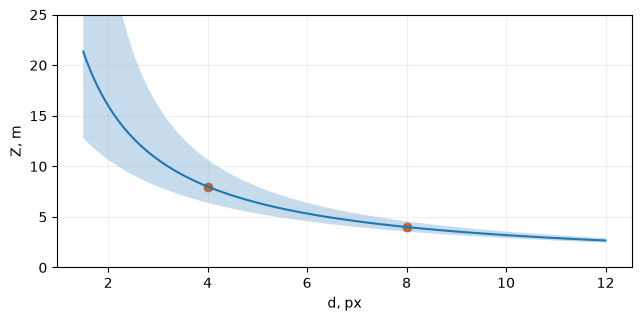

In [4]:
for d in (8, 4, 2):
    near, far = 32/(d+1), 32/(d-1)
    print(f"d = {d} px:  Z = {32/d:.2f} m,  [{near:.2f}, {far:.2f}] m")
disparities = np.linspace(1.5, 12, 150)
fig, ax = plt.subplots(figsize=(6.3, 3.1), layout="constrained")
ax.fill_between(disparities,32/(disparities+1),32/(disparities-1),alpha=.25)
ax.plot(disparities,32/disparities)
ax.scatter([4,8],[8,4],color="#b36639")
ax.set(xlabel="d, px",ylabel="Z, m",ylim=(0,25))
ax.grid(alpha=.2)
plt.show()

## Что попадает в съёмку

Камера перемещается небольшими шагами, пока в соседних кадрах остаются знакомые мелкие детали. Матовый неподвижный предмет, рассеянный свет и резкие кадры делают соответствия заметнее. Вторая дуга на другой высоте раскрывает верхнюю поверхность. При вращении на одном месте направление взгляда меняется, а центры камер почти совпадают. Лучи тогда плохо определяют глубину. При слишком большом шаге исчезают общие детали. Стекло, движущийся человек, повторяющийся орнамент и блик могут дать убедительную пару пикселей, относящихся к разным точкам мира.

Смаз стирает характерные углы. Автоэкспозиция способна сделать одну и ту же стену тёмной на первом кадре и светлой на следующем. Небольшая ошибка репроекции на видимых точках ничего не говорит про заднюю сторону, которой нет на снимках. До обучения полезнее всего увидеть сами кадры и положение камер.


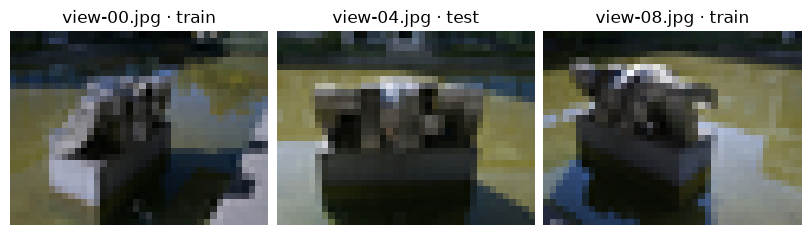

train: 8 test: 1


In [5]:
frames, seeds = photo_capture()
fig, axes = plt.subplots(1,3,figsize=(8,2.8),layout="constrained")
for ax, index in zip(axes,[0,4,8]):
    f=frames[index]
    ax.imshow(f["rgb"]); ax.set_title(f["name"]+" · "+f["split"]); ax.axis("off")
plt.show()
print("train:", sum(f["split"]=="train" for f in frames), "test:", sum(f["split"]=="test" for f in frames))


## Что находится в разреженной модели

В курсе лежат девять небольших снимков реальной сцены **struktur28_auto** из PhysicalAI-NuRec-PPISP (NVIDIA Corporation, CC BY 4.0). Внешние и внутренние параметры уже известны. Облако состоит из точек, а не из граней. Точка может иметь трек: перечень кадров и номеров двумерных наблюдений, где её удалось опознать. Средний кадр view-04 оставим для проверки изображения. Положения камер предоставлены для всего набора, поэтому опыт проверяет синтез картинки при **известной камере**. Лицензия, преобразования и происхождение указаны в [описании фотографий](https://github.com/HeinrichWirth/gaussian-splatting-course/tree/main/data/photographic-example).

В текстовом экспорте COLMAP файл **cameras.txt** хранит модель объектива и её параметры. У PINHOLE это ширина, высота и $f_x,f_y,c_x,c_y$. В **images.txt** первая строка каждого кадра содержит кватернион $(w,x,y,z)$, сдвиг $t$, идентификатор камеры и имя файла. Следующая строка хранит тройки «пиксель x, пиксель y, ID 3D-точки». Значение −1 обозначает метку без восстановленной 3D-точки. Файл **points3D.txt** связывает ID с координатами, RGB, ошибкой и треком. Идентификатор 93 не означает 93-ю строку.

COLMAP записывает преобразование **из мира в камеру**: $p_c=R p_w+t$. У центра камеры собственная координата равна нулю. Подставляем $0=R C+t$, переносим $t$ и умножаем на обратный поворот. Получается $C=-R^T t$. При единичном повороте и $t=(-0.4,0,0)$ камера стоит в $(+0.4,0,0)$. Это источник частой ошибки знака. Для нашего рендерера сохраняются $C$ и поворот **из камеры в мир** $R^T$.

У COLMAP центр первого пикселя равен $(0.5,0.5)$, у нашего массива $(0,0)$. При уменьшении фотографии с 160 до 40 пикселей коэффициент ширины $s=40/160=0.25$. В фокусе $f'_x=s f_x$, а главная точка $c'_x=s c_x-0.5$. Для исходного $c_x=80$ получаем 19.5, середину между 19 и 20. По вертикали используется фактическое отношение высот после округления. Простое уменьшение картинки без изменения $f_x$ сдвинет предсказанные пиксели.


In [6]:
cam = frames[0]["camera"]
R = np.array(cam["rotation"]).T  # world to camera
C = np.array(cam["center"])
t = -R @ C
assert np.allclose(-R.T @ t, C)
print("C:", C.round(3), "f:", np.round(cam["focal"],3), "c:", cam["principal"])

# A measured feature and its projection in the original (160 x 120) training view.
from reconstruction_demos import ROOT
from geometry3d import project_point, quaternion_matrix
model_dir = ROOT / "data/photographic-example/sparse/0"
rows = [line for line in (model_dir/"images.txt").read_text().splitlines() if not line.startswith("#")]
header = rows[0].split()
observation = rows[1].split()
u, v, point_id = float(observation[0]), float(observation[1]), observation[2]
point_rows = (model_dir/"points3D.txt").read_text().splitlines()
point = next(line.split() for line in point_rows if line and line.split()[0] == point_id)
X = np.array(point[1:4],float)
world_to_cam = quaternion_matrix([float(v) for v in header[1:5]])
t0 = np.array(header[5:8],float)
intrinsics = next(line.split() for line in (model_dir/"cameras.txt").read_text().splitlines()
                  if line and not line.startswith("#"))
fx, fy, cx, cy = map(float,intrinsics[4:])
observed = np.array([u-.5,v-.5])
camera_point = world_to_cam @ X + t0
pred = project_point(camera_point,[fx,fy],[cx-.5,cy-.5])
wrong = project_point(camera_point+[.08,0,0],[fx,fy],[cx-.5,cy-.5])
print("point ID", point_id, "observed:", observed.round(3), "projected:", pred.round(3))
print("reprojection error (px):",round(np.linalg.norm(pred-observed),3),
      "after translation:",round(np.linalg.norm(wrong-observed),3))


C: [-0.528  0.407 -4.51 ] f: [42.363 42.705] c: [19.5, 14.5]
point ID 26 observed: [ 30.667 113.767] projected: [ 30.989 113.992]
reprojection error (px): 0.393 after translation: 4.012


В строках выше взята настоящая наблюдаемая метка на первом снимке. Её ID связывает две координаты на снимке с тремя координатами облака. Сначала вычисляется положение в камере, затем пиксель. Если намеренно прибавить 0.08 единицы сцены к горизонтальному смещению камеры в преобразовании, предсказание уходит от измерения. Последняя строка показывает обе длины ошибки в пикселях.

## Как отыскать одну и ту же точку в трёх файлах

У скульптуры есть тёмные грани, на которых глаз замечает пересечения линий. Детектор выделяет местную деталь и сохраняет числовое описание её окрестности. При сопоставлении ищутся похожие описания. Одинаковые окна соседнего дома могут выглядеть почти одинаково, поэтому совпадение описаний — только кандидат. Если большинство деталей согласуется с одним взаимным положением камер, а одна пара уехала совсем в другую сторону, геометрическая проверка может отбросить её. Даже прошедшие такую проверку точки полезно посмотреть глазами.

В `images.txt` снимок занимает две строки. Верхняя сообщает, какая камера и какая поза относятся к файлу. В нижней повторяются тройки «горизонтальная координата, вертикальная координата, ID точки». Отрицательный ID в обычном экспорте означает наблюдение без восстановленной 3D-точки. В `points3D.txt` есть обратная связь — в каких изображениях и под какими индексами наблюдалась точка. ID может быть 148, даже если всего точек 117. После фильтрации в нумерации остаются пропуски. Искать 148-ю строку было бы ошибкой.

У точки 148 в нашем наборе четыре наблюдения. По двум построим положение в мире, а на третьем снимке посмотрим, куда оно попало. Ниже кадры шириной 80 пикселей. Метка в файле для снимка шириной 160 имеет координату от его левого края. Так, $u=100.08$ превращается в $100.08\cdot80/160-0.5=49.54$ в системе массива. Вычитание половины переводит начало отсчёта с края пикселя в его центр. Обратный путь из массива к полному снимку — сначала прибавить половину, затем разделить на масштаб. Порядок операций важен.

На увеличениях оранжевый крест обозначает измерение, синий круг — обратную проекцию общей точки. При изменении горизонтальной координаты второго креста положение реконструкции меняется. Крест на снимке 07 остаётся на месте. Этот снимок отделён **для проверки пары лучей**. В общей разреженной модели он участвовал. Фотография `view-04` по-прежнему лежит отдельно для другого опыта — оценки обученной сцены.

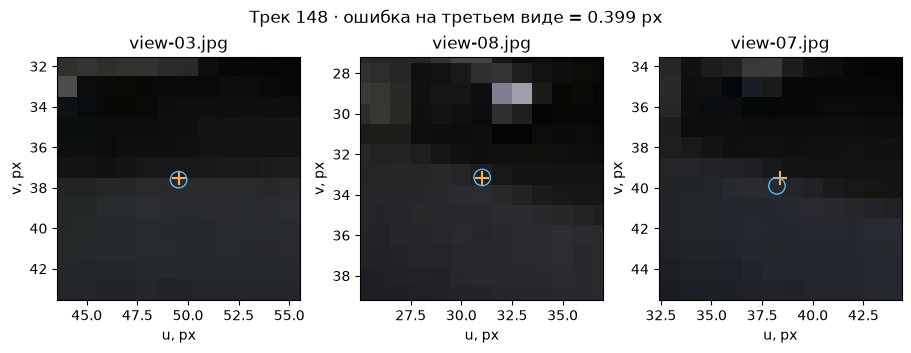

In [7]:
views80, _ = photo_capture(max_side=80)
track = inspect_photo.feature_track()
display(inspect_photo.track_figure(views80,track,lang=lang)); plt.close()
controls(lambda partner, offset: inspect_photo.track_figure(views80,track,partner,offset,lang),
         partner=[8,6], offset=(-3,3,.1,0))

## От отметки к лучу, от двух лучей обратно к отметке

Левый снимок дал пару $(u,v)$. Вычитание $(c_x,c_y)$ отсчитывает смещение от оси объектива. Деление горизонтальной разности на $f_x$, а вертикальной на $f_y$ даёт смещения на глубине **одна единица камеры**. Вместе с единицей впереди получается направление $((u-c_x)/f_x,(v-c_y)/f_y,1)$. Его длина пока произвольна. На глубине два все три числа можно удвоить, а пиксель останется прежним. Умножение на ориентацию камеры переносит направление в мир. Деление на его длину оставляет стрелку длины один.

Пусть первая камера стоит в $A$, вторая в $B$, а единичные стрелки — $r$ и $s$. После продвижения вдоль первого луча на расстояние $a$ точка находится в $A+ar$. На втором такое же рассуждение даёт $B+bs$. Числа $a$ и $b$ свои для каждой камеры. При идеальной отметке можно приравнять выражения. Перенос известных членов даёт $ar-bs=B-A$. Слева складываются два известных направления с двумя неизвестными длинами. Справа известен вектор между камерами. Для трёх координат это три строки уравнений. Шум обычно мешает двум неизвестным одновременно удовлетворить всем трём.

В коде `lstsq` подбирает длины, при которых сумма квадратов трёх оставшихся разностей минимальна. Получатся ближайшие друг к другу точки на двух прямых. Возьмём середину соединяющего их короткого отрезка и спроецируем её в снимок 07. Это простой способ построить проверяемую гипотезу. COLMAP при уточнении модели минимизирует ошибки **в изображениях**, а не расстояние между такими прямыми в мире.

Для пары 03 и 08 при нулевой поправке крест на третьем снимке находится около $(38.392,39.528)$, прогноз — $(38.231,39.894)$. Отсюда длина ошибки $\sqrt{(-0.161)^2+0.366^2}\approx0.40$ пикселя. При сдвиге второй отметки на три пикселя получаем около 2.01 пикселя. С парой 03 и 06 тот же сдвиг даёт примерно 3.44. Реальная фотопара сложнее параллельной схемы у стола. Здесь важны обе ориентации и направление ошибки относительно лучей.

<details><summary>Может ли нулевой зазор между двумя лучами означать неверную точку?</summary>

Да. Например, кандидат на правом снимке случайно оказался дальше вдоль той же эпиполярной линии — множества возможных проекций левого луча. Лучи могут пересечься буквально, только на другой глубине. Третий снимок с другой позиции проверяет именно это ложное пересечение. Уверенность ещё выше, когда и вид детали на всех трёх снимках согласуется.

</details>

In [8]:
by_name = {frame["name"]: frame for frame in views80}
a, c = by_name["view-03.jpg"], by_name["view-07.jpg"]
for second in ("view-06.jpg", "view-08.jpg"):
    b = by_name[second]
    for offset in (0., 1., 3.):
        p, gap = inspect_photo.intersect_observations(
            a, inspect_photo.measured_pixel(track,a), b, inspect_photo.measured_pixel(track,b)+[offset,0])
        miss = inspect_photo.reproject(p,c)-inspect_photo.measured_pixel(track,c)
        print(f"{second}: Δu={offset:.0f} px   gap={gap:.4f}   ||Δuv₇||={np.linalg.norm(miss):.3f} px")

view-06.jpg: Δu=0 px   gap=0.0113   ||Δuv₇||=0.452 px
view-06.jpg: Δu=1 px   gap=0.0144   ||Δuv₇||=1.197 px
view-06.jpg: Δu=3 px   gap=0.0689   ||Δuv₇||=3.437 px
view-08.jpg: Δu=0 px   gap=0.0048   ||Δuv₇||=0.399 px
view-08.jpg: Δu=1 px   gap=0.0160   ||Δuv₇||=0.622 px
view-08.jpg: Δu=3 px   gap=0.0590   ||Δuv₇||=2.013 px


## Свои фотографии

Для одной неподвижной сцены путь такой. Детектор находит метки. Сопоставление предлагает пары, геометрическая проверка отбрасывает несовместимые совпадения. Mapper регистрирует камеры, триангулирует точки и уточняет их вместе с камерами по ошибке репроекции. Под ошибкой здесь понимается длина вектора от наблюдаемого пикселя до предсказанного. Смещение на 3 пикселя вправо и 4 вниз даёт √(9+16) = 5 пикселей.

Ниже воспроизводимые команды для установленного COLMAP. В примере сырые фотографии лежат в capture/input, а пустые каталоги capture/sparse и capture/text уже созданы. `exhaustive_matcher` проверяет пары всех изображений и подходит небольшой серии. При нескольких компонентах номер 0 в примере заменяется на каталог связной модели с нужными видами.

```sh
colmap feature_extractor --database_path capture/database.db --image_path capture/input
colmap exhaustive_matcher --database_path capture/database.db
colmap mapper --database_path capture/database.db --image_path capture/input --output_path capture/sparse
colmap image_undistorter --image_path capture/input --input_path capture/sparse/0 --output_path capture/undistorted --output_type COLMAP
colmap model_converter --input_path capture/undistorted/sparse --output_path capture/text --output_type TXT
```

Теперь пути для учебного загрузчика — `capture/text` и `capture/undistorted/images`. Модель без дисторсии нужна потому, что наш объектив имеет только перспективное деление. Искажённая фотография и прямолинейная камера расходятся сильнее всего по краям. Большой набор можно уменьшить для опыта. Уменьшать изображение и пересчитывать камеру должен один загрузчик.

[Командная строка COLMAP](https://colmap.github.io/cli.html) · [Формат модели](https://colmap.github.io/format.html) · [Съёмка и восстановление](https://colmap.github.io/tutorial.html)

## Опыт

Два набора дают одинаковую среднюю ошибку репроекции. У первого камеры стоят почти на месте, у второго обходят предмет дугой. Одинаково ли хорошо определена глубина?

<details><summary>Разбор</summary>

Нет. У первого даже большое смещение точки вдоль луча почти не меняет её проекцию. Небольшая ошибка изображения совместима с большой неопределённостью по глубине. У второго пересекающиеся под разными углами лучи сильнее ограничивают положение. Полезно сравнить длины треков, взаимное положение камер и сами снимки.

</details>


## Что можно исправить до появления первой гауссианы

Получилась разреженная модель. Первое содержательное число — сколько **разных видов** видит одну деталь. Два наблюдения дают одну пару лучей. Третье добавляет независимое место, куда должна попасть точка. Но десять кадров, снятых почти из одного положения, ещё не дают сильного пересечения. Имеет смысл смотреть на длины треков вместе с расположением камер и покрытием предмета. В этих данных у 79 из 117 точек ровно три наблюдения. Это число описывает связи в наборе. Оно не гарантирует, что восстановлена верхушка скульптуры или пространство за ней.

Есть и незаметная на картинке свобода. Если увеличить расстояния между камерами и точки мира вдвое, горизонтальное смещение и глубина вырастут вместе. Отношение $X/Z$ останется прежним. Чтобы измерить скульптуру в сантиметрах, нужен известный размер, измеренная база или иное внешнее ограничение масштаба. Поэтому в опыте у стола база задана в метрах, а зазор в опыте на фотографиях выражен в единицах реконструкции.

<details><summary>Из 40 снимков зарегистрировались только 12, а у этих двенадцати малая ошибка. Что посмотреть до обучения?</summary>

Сначала имена зарегистрированных файлов и их позиции. Если это только передняя дуга, маленькая ошибка относится к видимым спереди деталям. Далее — общие треки на границе успешной серии. Разрыв между последним резким боковым кадром и дальним задним может оставить две отдельные модели. Несколько перекрывающихся кадров между дугами дадут информацию, которой не добавит увеличение числа шагов обучения. Если же соответствия есть, а на всех углах снимка остаются направленные ошибки, следующий подозреваемый — объектив или несогласованное изменение размера.

</details>

После этих проверок в следующий урок переходят три вещи: снимки, камеры в той же системе координат и разреженные цветные точки. Пустое место в облаке пока означает только отсутствие надёжного трека. При обучении удастся заполнить некоторые промежутки, если туда действительно смотрят камеры.